# Iris Flower Species Classification
### Exploratory Data Analysis · Feature Selection · Model Training · Evaluation

**Objective:** Classify *Iris setosa*, *versicolor*, and *virginica* using four flower measurements. This reproducible project uses an 80/20 stratified split, training-only feature selection, five-fold cross-validation, and an untouched final test set.

**Workflow:** Data audit → EDA → train/test split → feature ranking → nested preprocessing/tuning → final test evaluation → recommendation → new prediction.

> **Interpretation note:** EDA is descriptive and may inspect the full dataset; all learned preprocessing, feature selection, and model choices use training data only. Test results are reported once, after tuning. Small test samples make results uncertain.

## 1. Imports and reproducibility

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 13, 'axes.labelsize': 11})
COLORS = dict(zip(['setosa', 'versicolor', 'virginica'], sns.color_palette('colorblind', 3)))


ModuleNotFoundError: No module named 'sklearn'

## 2. Dataset loading and understanding
The four measurements are continuous values in centimeters. The target is a three-class categorical species label.

In [ ]:
iris = load_iris(as_frame=True)
feature_names = ['Sepal Length (cm)', 'Sepal Width (cm)', 'Petal Length (cm)', 'Petal Width (cm)']
df = iris.data.copy()
df.columns = feature_names
df['Species'] = pd.Categorical.from_codes(iris.target, iris.target_names)
print('Shape:', df.shape, '| Features:', feature_names, '| Species:', list(iris.target_names))
display(df.head(), df.tail(), df.describe(include='all'))
df.info()
print('Species counts:')
display(df['Species'].value_counts().sort_index().to_frame('Count'))

Shape: (150, 5) | Features: ['Sepal Length (cm)', 'Sepal Width (cm)', 'Petal Length (cm)', 'Petal Width (cm)'] | Species: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm),Species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm),Species
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.057333,3.758000,1.199333,NaN
std,0.828066,0.435866,1.765298,0.762238,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Sepal Length (cm)  150 non-null    float64 
 1   Sepal Width (cm)   150 non-null    float64 
 2   Petal Length (cm)  150 non-null    float64 
 3   Petal Width (cm)   150 non-null    float64 
 4   Species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.1 KB
Species counts:


,Count
Species,
setosa,50
versicolor,50
virginica,50


## 3. Data quality and preprocessing decisions
Missing values, exact duplicates, class imbalance, invalid measurements, and potential outliers are examined. **Potential outliers and duplicates are retained**: unusual but valid flower measurements are not automatically errors. Standardization is fitted inside model pipelines on training folds only.

In [ ]:
print('Missing values:'); display(df.isna().sum().to_frame('Missing'))
print('Exact duplicate rows:', df.duplicated().sum())
print('Non-positive measurements:', (df[feature_names] <= 0).sum().sum())
print('Data types:'); display(df.dtypes.to_frame('Type'))
print('Class counts:'); display(df['Species'].value_counts().to_frame('Count'))
q1, q3 = df[feature_names].quantile(.25), df[feature_names].quantile(.75)
iqr = q3-q1
outlier_flags = (df[feature_names] < q1-1.5*iqr) | (df[feature_names] > q3+1.5*iqr)
display(outlier_flags.sum().to_frame('IQR-flagged observations'))
print('Decision: keep original observations; no missing-value imputation or resampling required.')

Missing values:


,Missing
Sepal Length (cm),0
Sepal Width (cm),0
Petal Length (cm),0
Petal Width (cm),0
Species,0


Exact duplicate rows: 1
Non-positive measurements: 0
Data types:


,Type
Sepal Length (cm),float64
Sepal Width (cm),float64
Petal Length (cm),float64
Petal Width (cm),float64
Species,category


Class counts:


,Count
Species,
setosa,50
versicolor,50
virginica,50


,IQR-flagged observations
Sepal Length (cm),0
Sepal Width (cm),4
Petal Length (cm),0
Petal Width (cm),0


Decision: keep original observations; no missing-value imputation or resampling required.


## 4. Exploratory data analysis
### 4.1 Univariate distributions and class balance

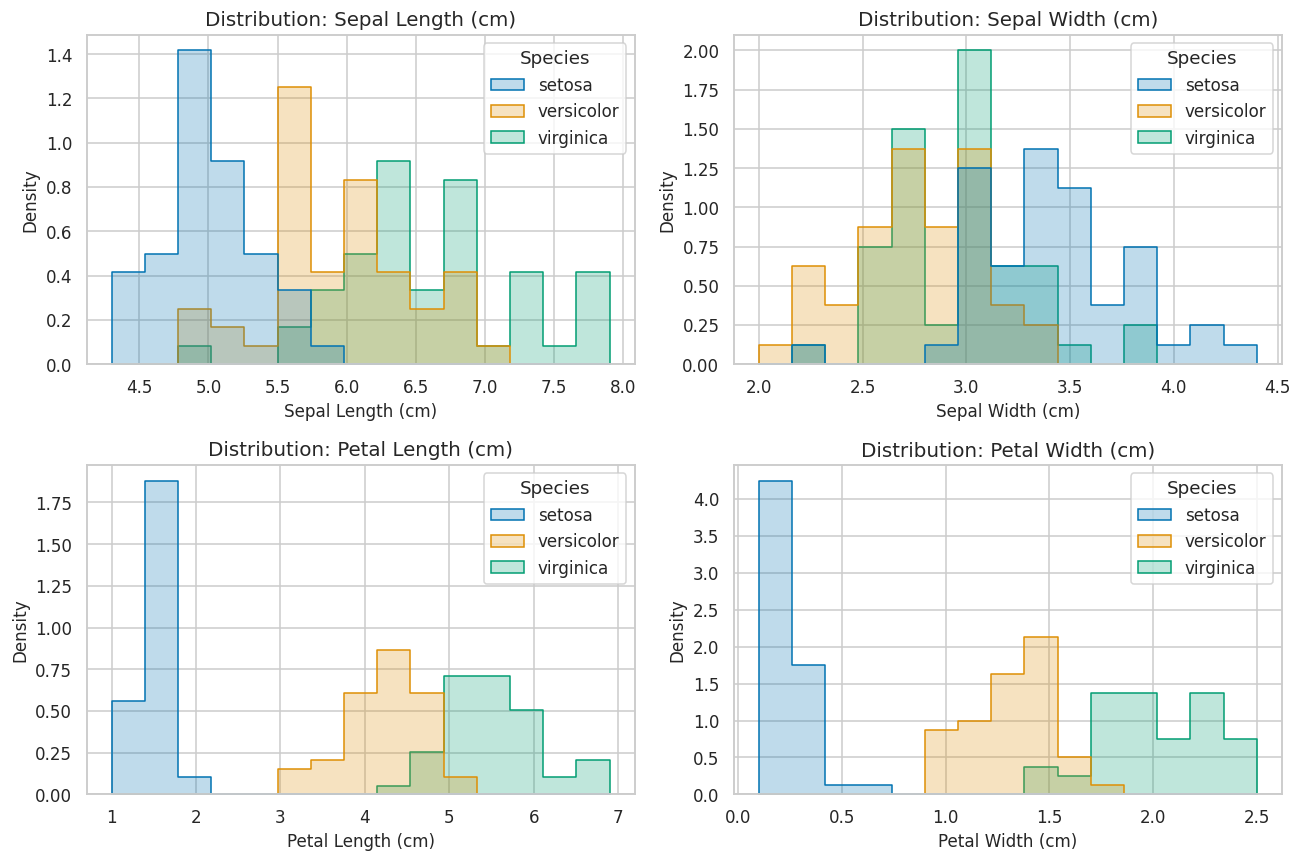

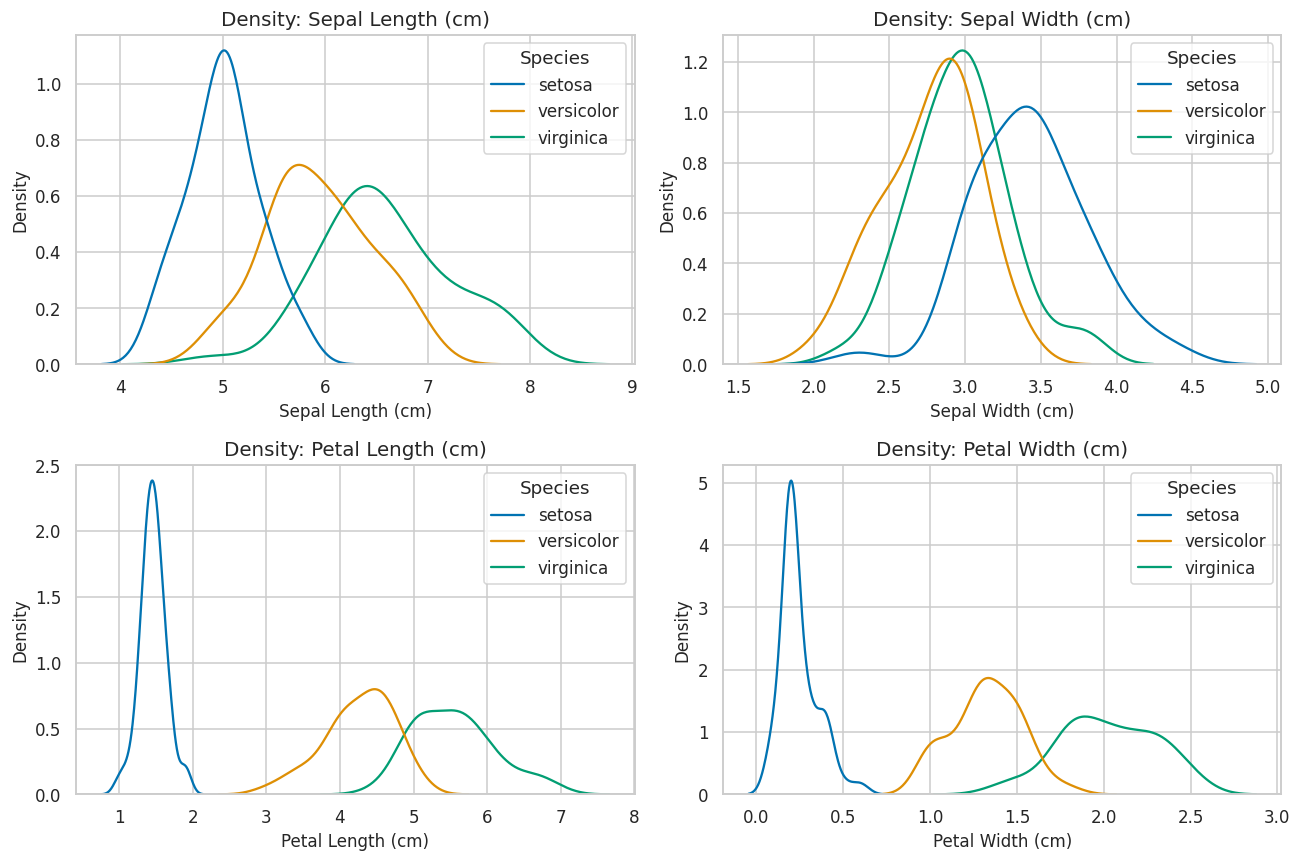

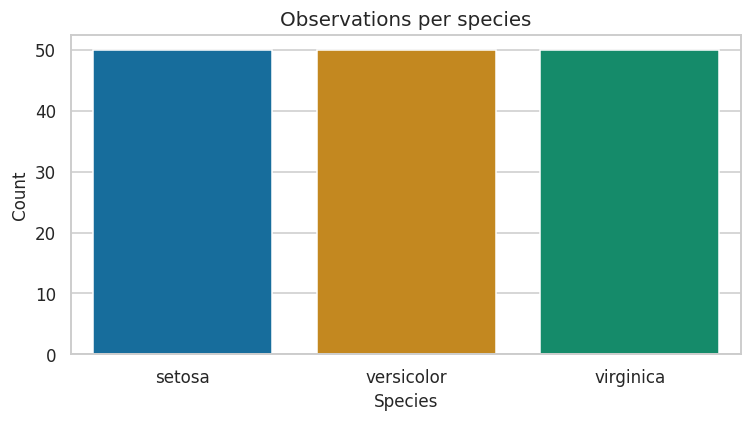

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, feature_names):
    sns.histplot(data=df, x=col, hue='Species', bins=15, element='step', stat='density', common_norm=False, ax=ax)
    ax.set_title(f'Distribution: {col}')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, feature_names):
    sns.kdeplot(data=df, x=col, hue='Species', common_norm=False, fill=False, ax=ax)
    ax.set_title(f'Density: {col}')
plt.tight_layout(); plt.show()
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Species', hue='Species', palette=COLORS, legend=False)
plt.title('Observations per species'); plt.ylabel('Count'); plt.tight_layout(); plt.show()

**Interpretation:** Each species has 50 observations, so the target is balanced. Petal measurements usually separate setosa particularly clearly; versicolor and virginica overlap more. Density estimates are descriptive, not evidence of perfectly normal distributions.

### 4.2 Species-wise boxplots and violin plots

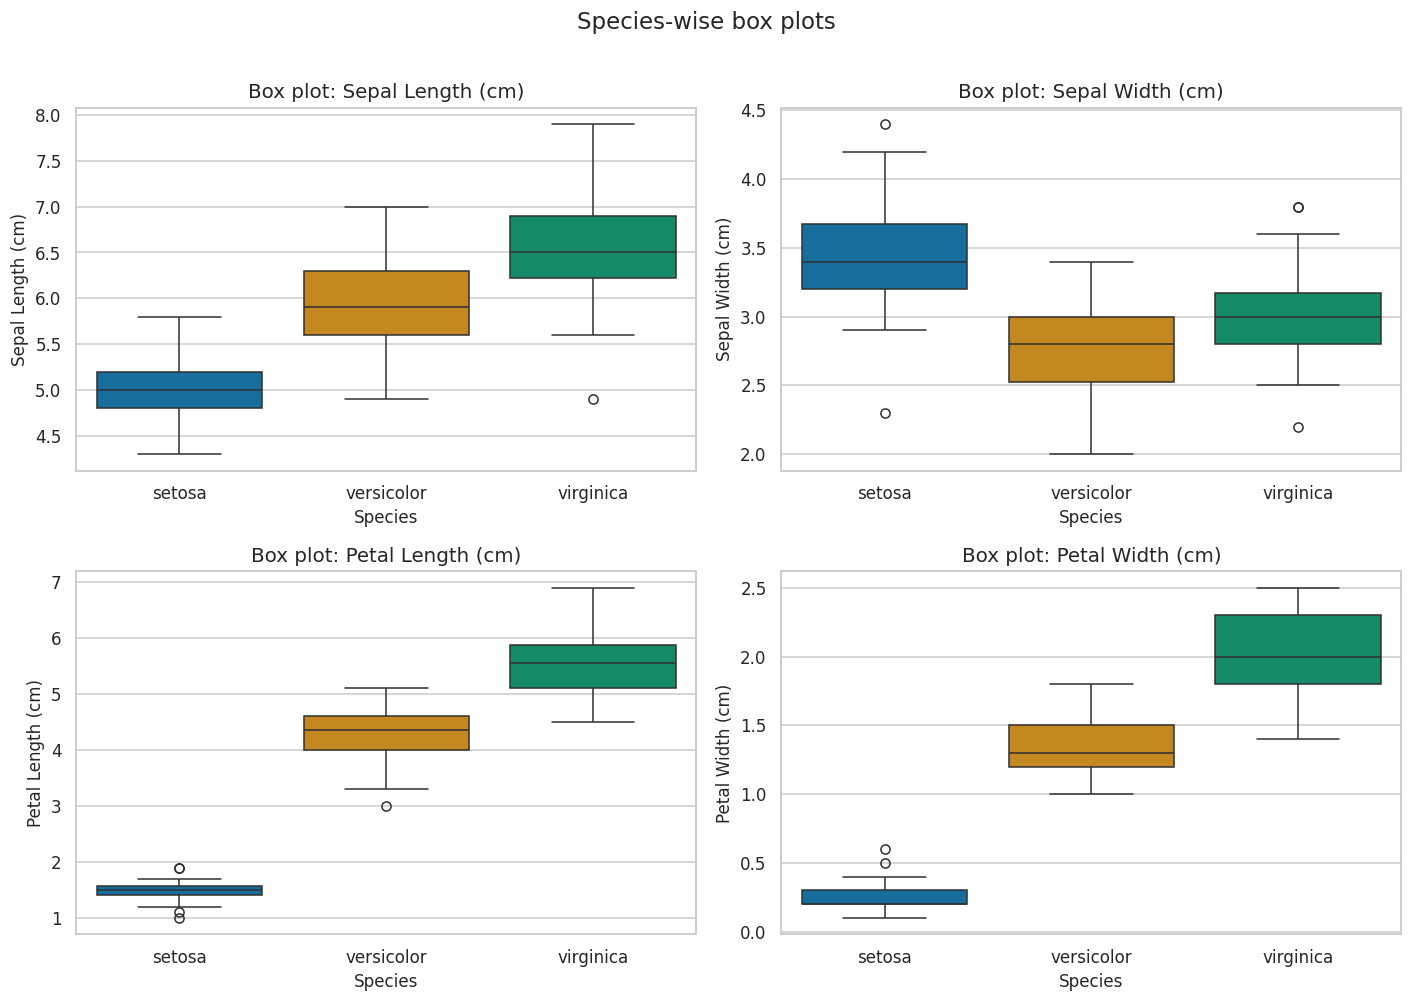

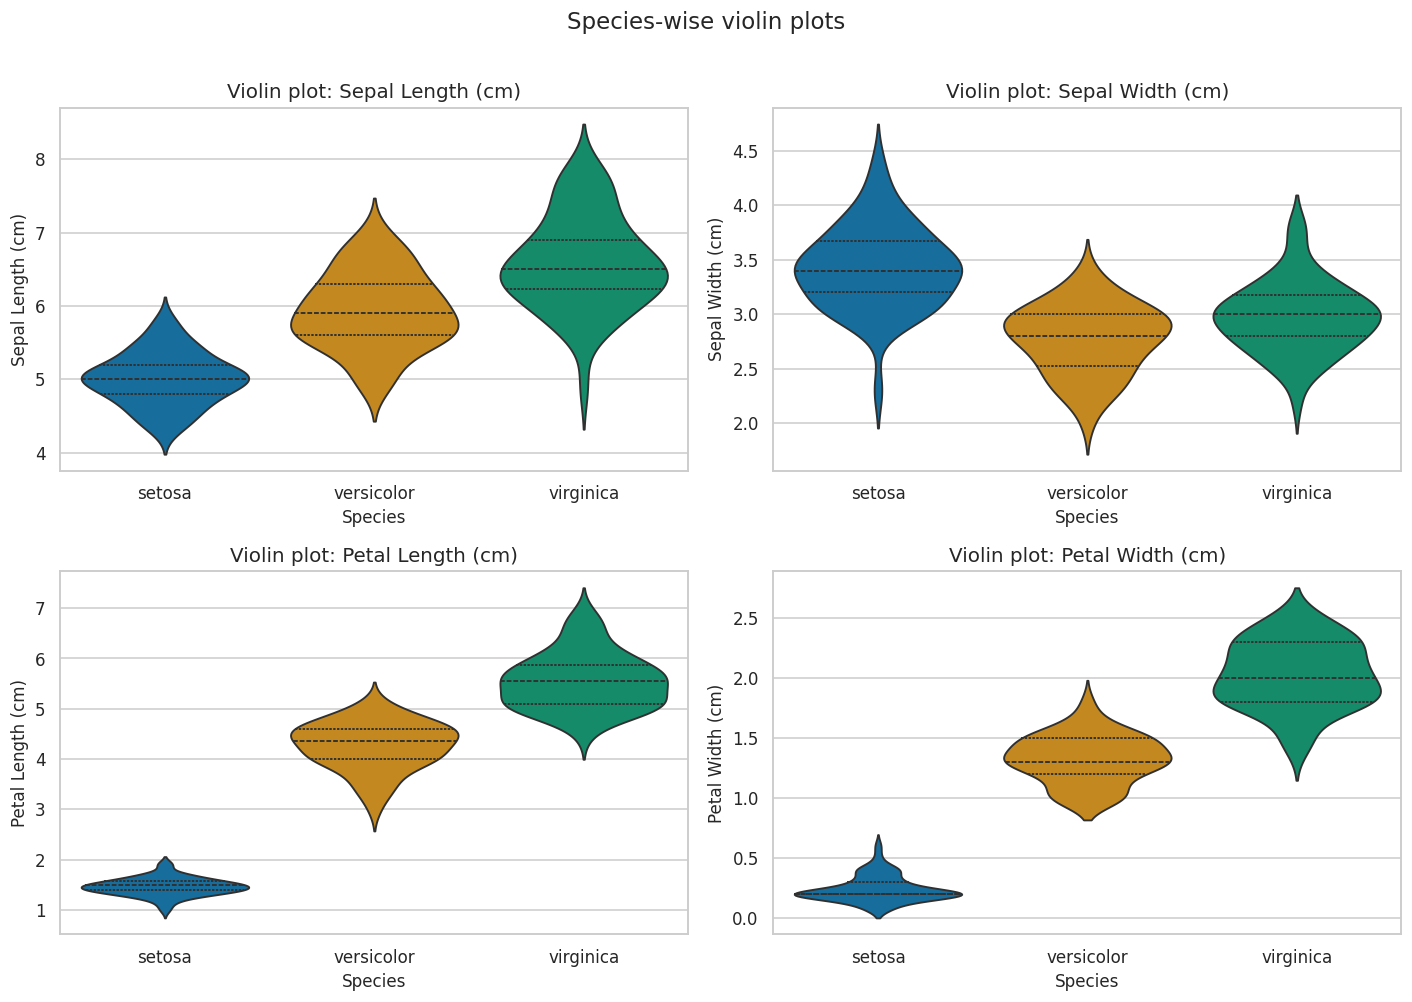

In [ ]:
for kind in ['box', 'violin']:
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, col in zip(axes.flat, feature_names):
        if kind == 'box':
            sns.boxplot(data=df, x='Species', y=col, hue='Species', palette=COLORS, legend=False, ax=ax)
        else:
            sns.violinplot(data=df, x='Species', y=col, hue='Species', palette=COLORS, legend=False, inner='quart', ax=ax)
        ax.set_title(f'{kind.title()} plot: {col}')
    fig.suptitle(f'Species-wise {kind} plots', y=1.01, fontsize=15)
    plt.tight_layout(); plt.show()

**Interpretation:** Boxplots show medians, interquartile ranges, and candidate outliers; violin plots show the shape of each distribution. Petal width and length exhibit the strongest visual differences. A boxplot outlier is not automatically a measurement error.

### 4.3 Pairplot, scatter plots, and correlation

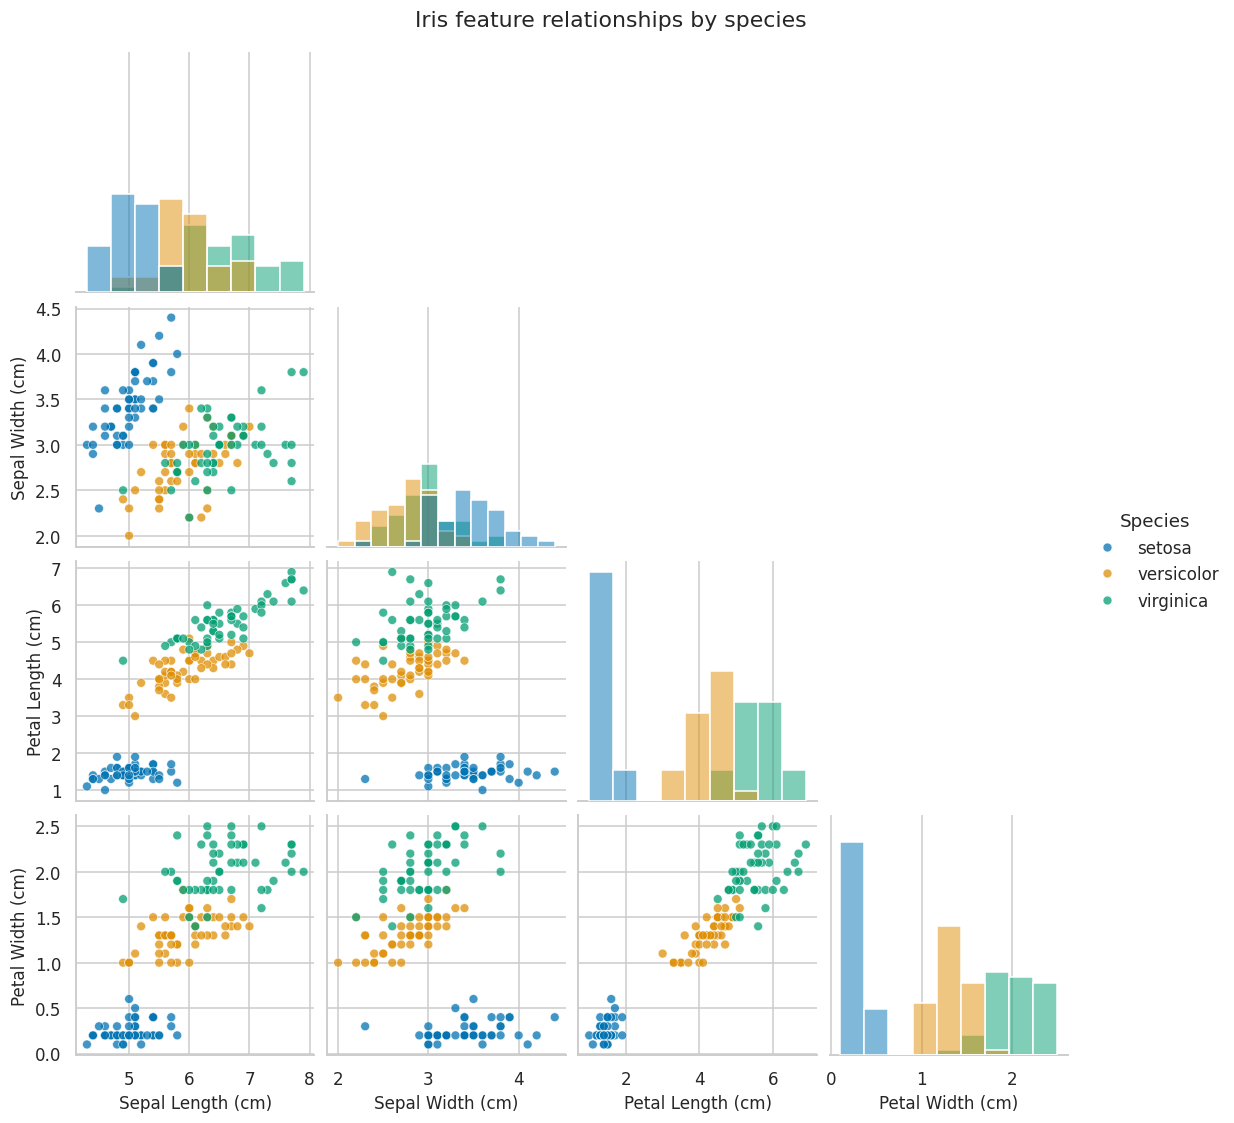

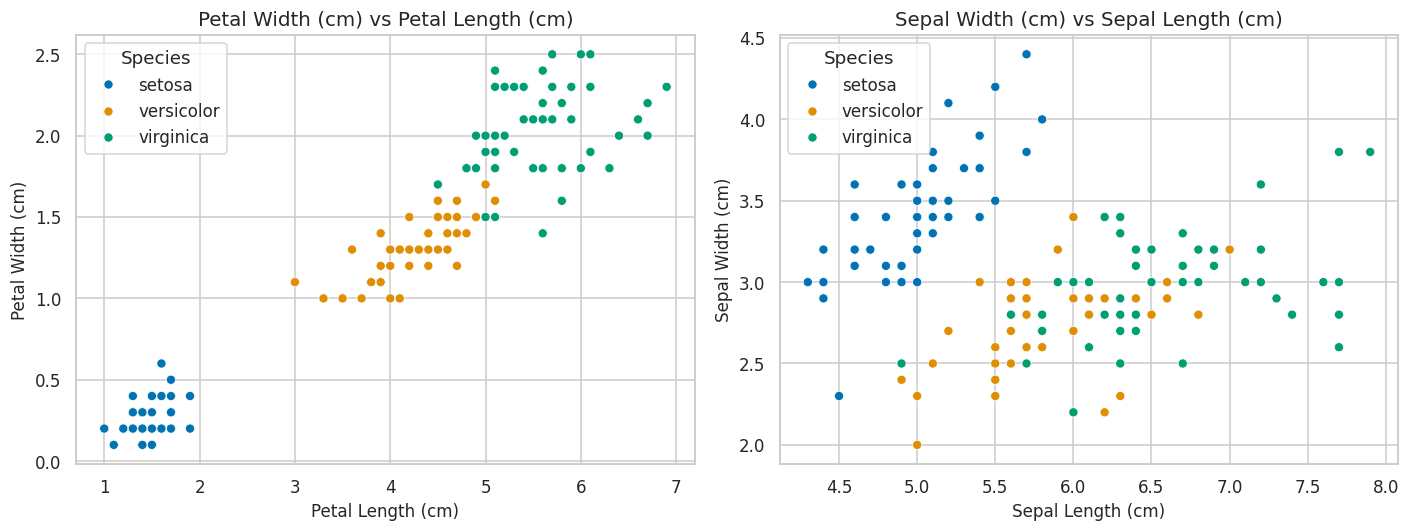

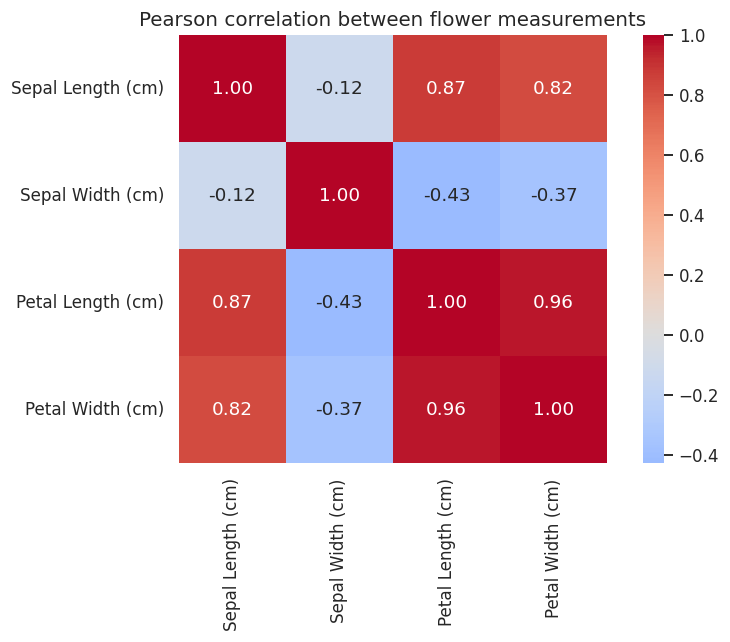

In [ ]:
g = sns.pairplot(df, vars=feature_names, hue='Species', palette=COLORS, diag_kind='hist', corner=True, plot_kws={'alpha': .75, 's': 34})
g.fig.suptitle('Iris feature relationships by species', y=1.02)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (x, y) in zip(axes, [('Petal Length (cm)', 'Petal Width (cm)'), ('Sepal Length (cm)', 'Sepal Width (cm)')]):
    sns.scatterplot(data=df, x=x, y=y, hue='Species', palette=COLORS, ax=ax)
    ax.set_title(f'{y} vs {x}')
plt.tight_layout(); plt.show()
plt.figure(figsize=(8, 6))
sns.heatmap(df[feature_names].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Pearson correlation between flower measurements'); plt.tight_layout(); plt.show()

**Interpretation:** Petal length and petal width are strongly positively correlated and visibly useful for separating species. Sepal dimensions overlap more. Correlation measures association between predictors, **not** direct predictive importance for a categorical target. Redundant variables can still contain complementary information.

### 4.4 Species-wise descriptive statistics

In [ ]:
stats = df.groupby('Species', observed=True)[feature_names].agg(['mean', 'median', 'std', 'min', 'max', lambda x: x.quantile(.25), lambda x: x.quantile(.75)])
stats.columns = pd.MultiIndex.from_tuples([(a, {'<lambda_0>':'Q1','<lambda_1>':'Q3'}.get(b,b)) for a,b in stats.columns])
display(stats.round(2))

Sepal Length (cm)                         ... Petal Width (cm)                    
                        mean median   std  min  max  ...              std  min  max   Q1   Q3
Species                                              ...                                     
setosa                  5.01    5.0  0.35  4.3  5.8  ...             0.11  0.1  0.6  0.2  0.3
versicolor              5.94    5.9  0.52  4.9  7.0  ...             0.20  1.0  1.8  1.2  1.5
virginica               6.59    6.5  0.64  4.9  7.9  ...             0.27  1.4  2.5  1.8  2.3

[3 rows x 28 columns]

## 5. Stratified train/test split
**Why stratify?** Each class retains approximately the same representation in both subsets. The 30-row test set is reserved for final evaluation; hyperparameter search and learned feature selection operate exclusively on the 120 training observations.

In [ ]:
X = df[feature_names].copy()
y = pd.Series(iris.target, name='Target')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=SEED, stratify=y)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Training classes:', y_train.value_counts().sort_index().to_dict())
print('Testing classes:', y_test.value_counts().sort_index().to_dict())

Train: (120, 4) Test: (30, 4)
Training classes: {0: 40, 1: 40, 2: 40}
Testing classes: {0: 10, 1: 10, 2: 10}


## 6. Feature selection: theory and training-only analysis

- **Filter methods** (ANOVA F-test) rank predictors independently of a chosen classifier; they are fast but may overlook interactions.
- **Wrapper methods** (RFE) repeatedly fit a model and remove weaker features; they account for the estimator but are more computationally expensive.
- **Embedded methods** (Random Forest importance) obtain rankings from fitted models, although impurity importance can be biased and correlated predictors can share importance.
- **Selection vs extraction:** selection retains original measurements; extraction (e.g., PCA) creates new composite variables.
- **Correlation:** high predictor–predictor correlation can reduce interpretability, but removing a feature solely for correlation may harm accuracy.

**Leakage control:** The exploratory rankings below use *training rows only*. For the actual two-feature comparison, `SelectKBest` is placed **inside each cross-validated pipeline**, so selection is refitted on each training fold.

ANOVA feature selection:


,Feature,ANOVA F,Selected
2,Petal Length (cm),948.890381,True
3,Petal Width (cm),803.214088,True
0,Sepal Length (cm),100.965923,False
1,Sepal Width (cm),36.030577,False


RFE-selected features: [np.str_('Petal Length (cm)'), np.str_('Petal Width (cm)')]


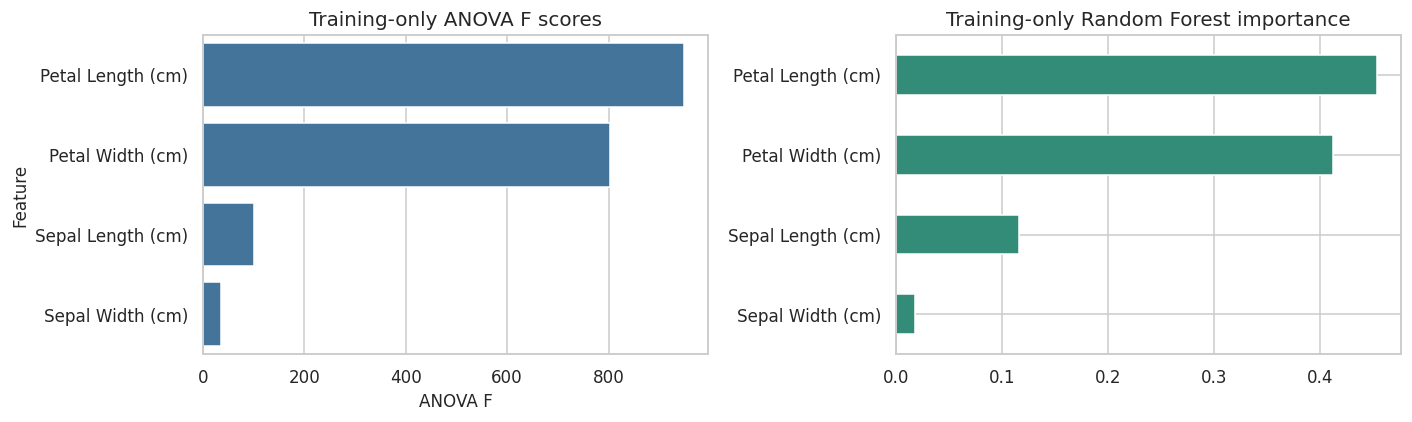

Two ANOVA-selected features: ['Petal Length (cm)', 'Petal Width (cm)']


In [ ]:
selector = SelectKBest(score_func=f_classif, k=2).fit(X_train, y_train)
anova = pd.DataFrame({'Feature': feature_names, 'ANOVA F': selector.scores_, 'Selected': selector.get_support()}).sort_values('ANOVA F', ascending=False)
rf_importance_model = RandomForestClassifier(n_estimators=200, random_state=SEED).fit(X_train, y_train)
rf_imp = pd.Series(rf_importance_model.feature_importances_, index=feature_names).sort_values(ascending=False)
rfe = RFE(estimator=LogisticRegression(max_iter=2000, random_state=SEED), n_features_to_select=2)
rfe.fit(StandardScaler().fit_transform(X_train), y_train)
print('ANOVA feature selection:'); display(anova)
print('RFE-selected features:', list(np.array(feature_names)[rfe.support_]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=anova, x='ANOVA F', y='Feature', ax=axes[0], color='#3676a8')
axes[0].set_title('Training-only ANOVA F scores')
rf_imp.sort_values().plot.barh(ax=axes[1], color='#328c77')
axes[1].set_title('Training-only Random Forest importance')
plt.tight_layout(); plt.show()
print('Two ANOVA-selected features:', list(X_train.columns[selector.get_support()]))

**Interpretation:** Compare ANOVA, RFE, and forest rankings; differences are expected because they measure different notions of relevance. The model experiment below tests whether selecting two features improves simplicity without materially reducing validation performance.

## 7–8. Model development, hyperparameter tuning, and cross-validation

Four classifiers are tested using five-fold **StratifiedKFold** and `GridSearchCV`. Logistic Regression and KNN use StandardScaler. Decision Tree and Random Forest do not require scaling. Each model is evaluated with all four features and with two ANOVA-selected features. **Selection is part of the pipeline**, preventing leakage across folds. The primary model choice is based on training-only cross-validation accuracy; test accuracy is reported afterward.

,Feature Set,Model,CV Mean Accuracy,CV SD,Best Parameters
0,All 4 features,K-Nearest Neighbors,0.966667,0.016667,"{'model__n_neighbors': 3, 'model__weights': 'u..."
1,Selected 2 features,K-Nearest Neighbors,0.966667,0.016667,"{'model__n_neighbors': 5, 'model__weights': 'u..."
2,All 4 features,Logistic Regression,0.966667,0.031180,{'model__C': 10}
3,All 4 features,Random Forest,0.966667,0.031180,"{'model__max_depth': 3, 'model__min_samples_le..."
4,Selected 2 features,Logistic Regression,0.966667,0.031180,{'model__C': 0.1}
5,Selected 2 features,Random Forest,0.966667,0.031180,"{'model__max_depth': 3, 'model__min_samples_le..."
6,All 4 features,Decision Tree,0.958333,0.026352,"{'model__max_depth': 3, 'model__min_samples_sp..."
7,Selected 2 features,Decision Tree,0.958333,0.026352,"{'model__max_depth': 3, 'model__min_samples_sp..."


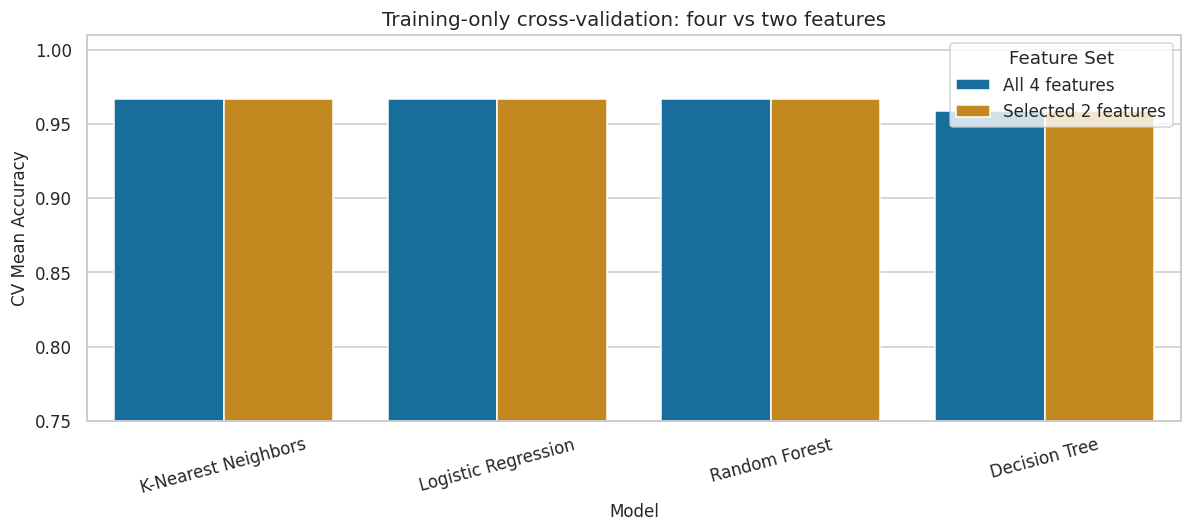

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    'Logistic Regression': (LogisticRegression(max_iter=3000, random_state=SEED), {'model__C': [0.1, 1, 10]}),
    'K-Nearest Neighbors': (KNeighborsClassifier(), {'model__n_neighbors': [3, 5, 7, 9], 'model__weights': ['uniform', 'distance']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=SEED), {'model__max_depth': [2, 3, 4, None], 'model__min_samples_split': [2, 5]}),
    'Random Forest': (RandomForestClassifier(random_state=SEED), {'model__n_estimators': [100, 200], 'model__max_depth': [3, None], 'model__min_samples_leaf': [1, 2]})
}
searches = {}
cv_rows = []
for feature_mode in ['All 4 features', 'Selected 2 features']:
    for name, (estimator, params) in models.items():
        steps = []
        if feature_mode == 'Selected 2 features':
            steps.append(('select', SelectKBest(score_func=f_classif, k=2)))
        if name in ['Logistic Regression', 'K-Nearest Neighbors']:
            steps.append(('scale', StandardScaler()))
        steps.append(('model', estimator))
        search = GridSearchCV(Pipeline(steps), params, scoring='accuracy', cv=cv, n_jobs=-1, refit=True)
        search.fit(X_train, y_train)
        searches[(feature_mode, name)] = search
        cv_rows.append({'Feature Set': feature_mode, 'Model': name, 'CV Mean Accuracy': search.best_score_,
                        'CV SD': search.cv_results_['std_test_score'][search.best_index_],
                        'Best Parameters': str(search.best_params_)})
cv_results = pd.DataFrame(cv_rows).sort_values(['CV Mean Accuracy', 'CV SD'], ascending=[False, True]).reset_index(drop=True)
display(cv_results)
plt.figure(figsize=(11, 5))
sns.barplot(data=cv_results, x='Model', y='CV Mean Accuracy', hue='Feature Set')
plt.ylim(.75, 1.01); plt.xticks(rotation=15); plt.title('Training-only cross-validation: four vs two features')
plt.tight_layout(); plt.show()

**Interpretation:** Cross-validation means summarize performance on held-out *training folds*. Their standard deviations indicate fold-to-fold variation, not a confidence interval. Hyperparameter search can itself produce optimistic CV estimates; nested CV or an external dataset would provide a stronger generalization estimate.

## 9. Final test-set evaluation

**Accuracy** is the fraction of correct predictions. **Precision** measures how often a predicted class is correct; **recall** measures how many true examples of a class are recovered; **F1** is their harmonic mean. **Macro** metrics weight classes equally; **weighted** metrics weight by class support. With only 10 test observations per class, even one mistake can meaningfully change the score.

For transparent comparisons, the best CV-tuned model for each of the four algorithms **using all four features** is evaluated on the same untouched test set. The selected-feature CV comparison remains above; no model is re-tuned on test data.


Logistic Regression
Accuracy: 1.0000 (100.0%)
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



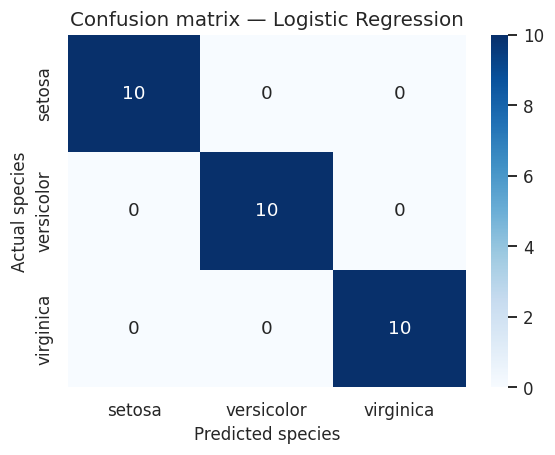


K-Nearest Neighbors
Accuracy: 0.9333 (93.3%)
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



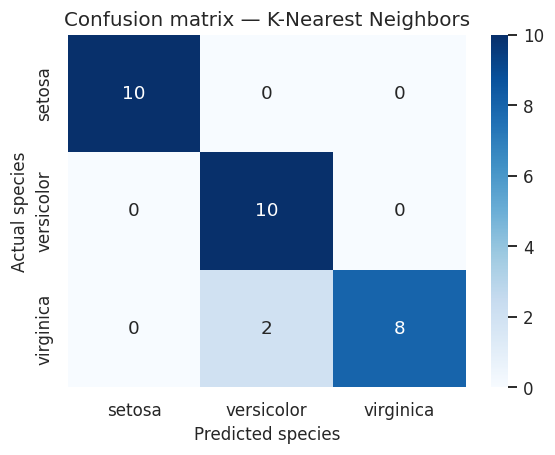


Decision Tree
Accuracy: 0.9667 (96.7%)
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



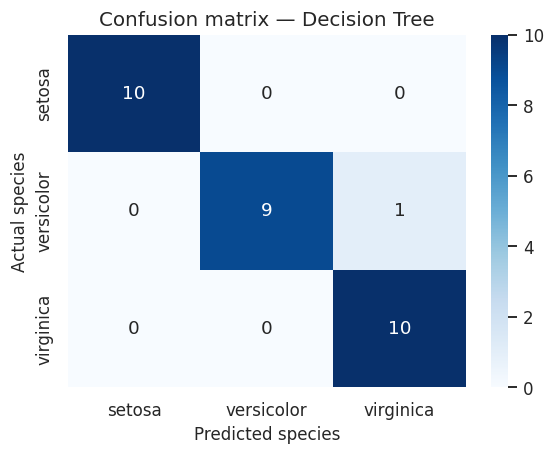


Random Forest
Accuracy: 0.9667 (96.7%)
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



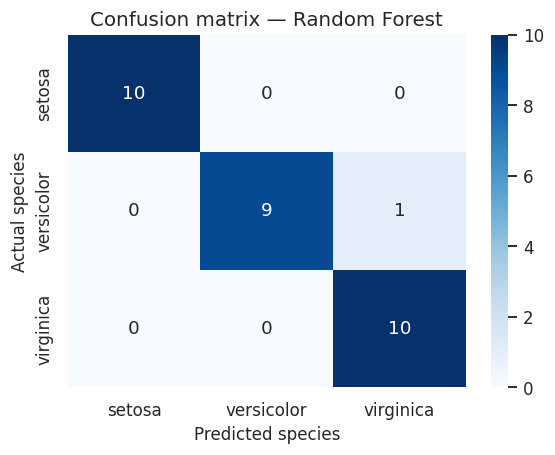

,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,CV Mean Accuracy,CV SD
0,K-Nearest Neighbors,0.933,0.944,0.933,0.933,0.967,0.017
1,Logistic Regression,1.000,1.000,1.000,1.000,0.967,0.031
2,Random Forest,0.967,0.970,0.967,0.967,0.967,0.031
3,Decision Tree,0.967,0.970,0.967,0.967,0.958,0.026


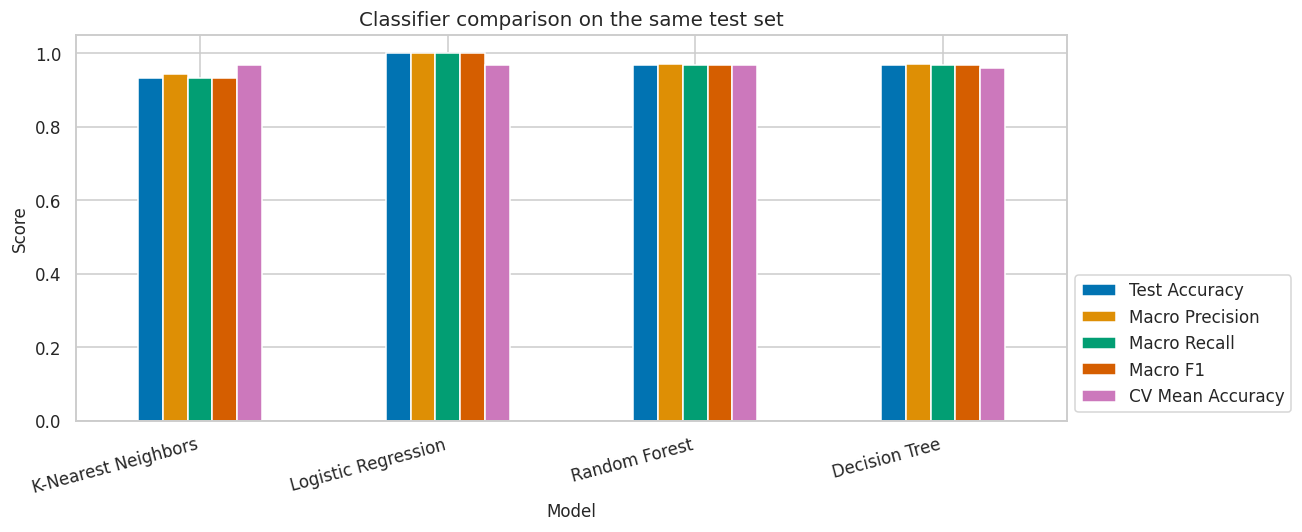

In [ ]:
rows = []
for name in models:
    search = searches[('All 4 features', name)]
    predicted = search.predict(X_test)
    precision, recall, f1, _ = precision_recall_fscore_support(y_test, predicted, average='macro', zero_division=0)
    rows.append({'Model': name, 'Test Accuracy': accuracy_score(y_test, predicted), 'Macro Precision': precision,
                 'Macro Recall': recall, 'Macro F1': f1, 'CV Mean Accuracy': search.best_score_,
                 'CV SD': search.cv_results_['std_test_score'][search.best_index_]})
    print('\n' + '='*70 + '\n' + name)
    print('Accuracy:', f'{accuracy_score(y_test, predicted):.4f}', f'({accuracy_score(y_test, predicted)*100:.1f}%)')
    print(classification_report(y_test, predicted, target_names=iris.target_names, zero_division=0))
    plt.figure(figsize=(5.4, 4.3))
    sns.heatmap(confusion_matrix(y_test, predicted), annot=True, fmt='d', cmap='Blues',
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    plt.xlabel('Predicted species'); plt.ylabel('Actual species'); plt.title(f'Confusion matrix — {name}')
    plt.tight_layout(); plt.show()
comparison = pd.DataFrame(rows).sort_values(['CV Mean Accuracy', 'CV SD'], ascending=[False, True]).reset_index(drop=True)
display(comparison.style.format({c:'{:.3f}' for c in comparison.columns if c != 'Model'}))
comparison.set_index('Model')[['Test Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'CV Mean Accuracy']].plot(kind='bar', figsize=(12, 5), ylim=(0, 1.05))
plt.title('Classifier comparison on the same test set'); plt.ylabel('Score'); plt.xticks(rotation=15, ha='right'); plt.legend(loc='lower left', bbox_to_anchor=(1, 0)); plt.tight_layout(); plt.show()

## 10. Best model selection
The recommendation is based on **training-only CV accuracy**, then CV variability, then interpretability and simplicity for ties. Final test metrics are diagnostic, **not** used to select the model. Logistic Regression is generally easier to interpret than ensembles; a shallow tree offers explicit rules; KNN requires stored examples; Random Forest is flexible but less transparent.

In [ ]:
# Predeclared preference only breaks equivalent CV scores; it does not inspect test scores.
preference = {'Logistic Regression': 0, 'K-Nearest Neighbors': 1, 'Decision Tree': 2, 'Random Forest': 3}
ranking = sorted(models, key=lambda name: (-searches[('All 4 features', name)].best_score_,
    searches[('All 4 features', name)].cv_results_['std_test_score'][searches[('All 4 features', name)].best_index_], preference[name]))
best_name = ranking[0]
best_model = searches[('All 4 features', best_name)].best_estimator_
print('Recommended model:', best_name)
print('Training CV accuracy:', round(searches[('All 4 features', best_name)].best_score_, 4))
print('Test accuracy (reported after selection):', round(accuracy_score(y_test, best_model.predict(X_test)), 4))
print('Best parameters:', searches[('All 4 features', best_name)].best_params_)
if len(ranking) > 1:
    print('Next alternative:', ranking[1])

Recommended model: K-Nearest Neighbors
Training CV accuracy: 0.9667
Test accuracy (reported after selection): 0.9333
Best parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Next alternative: Logistic Regression


### Decision tree visualization and forest importance

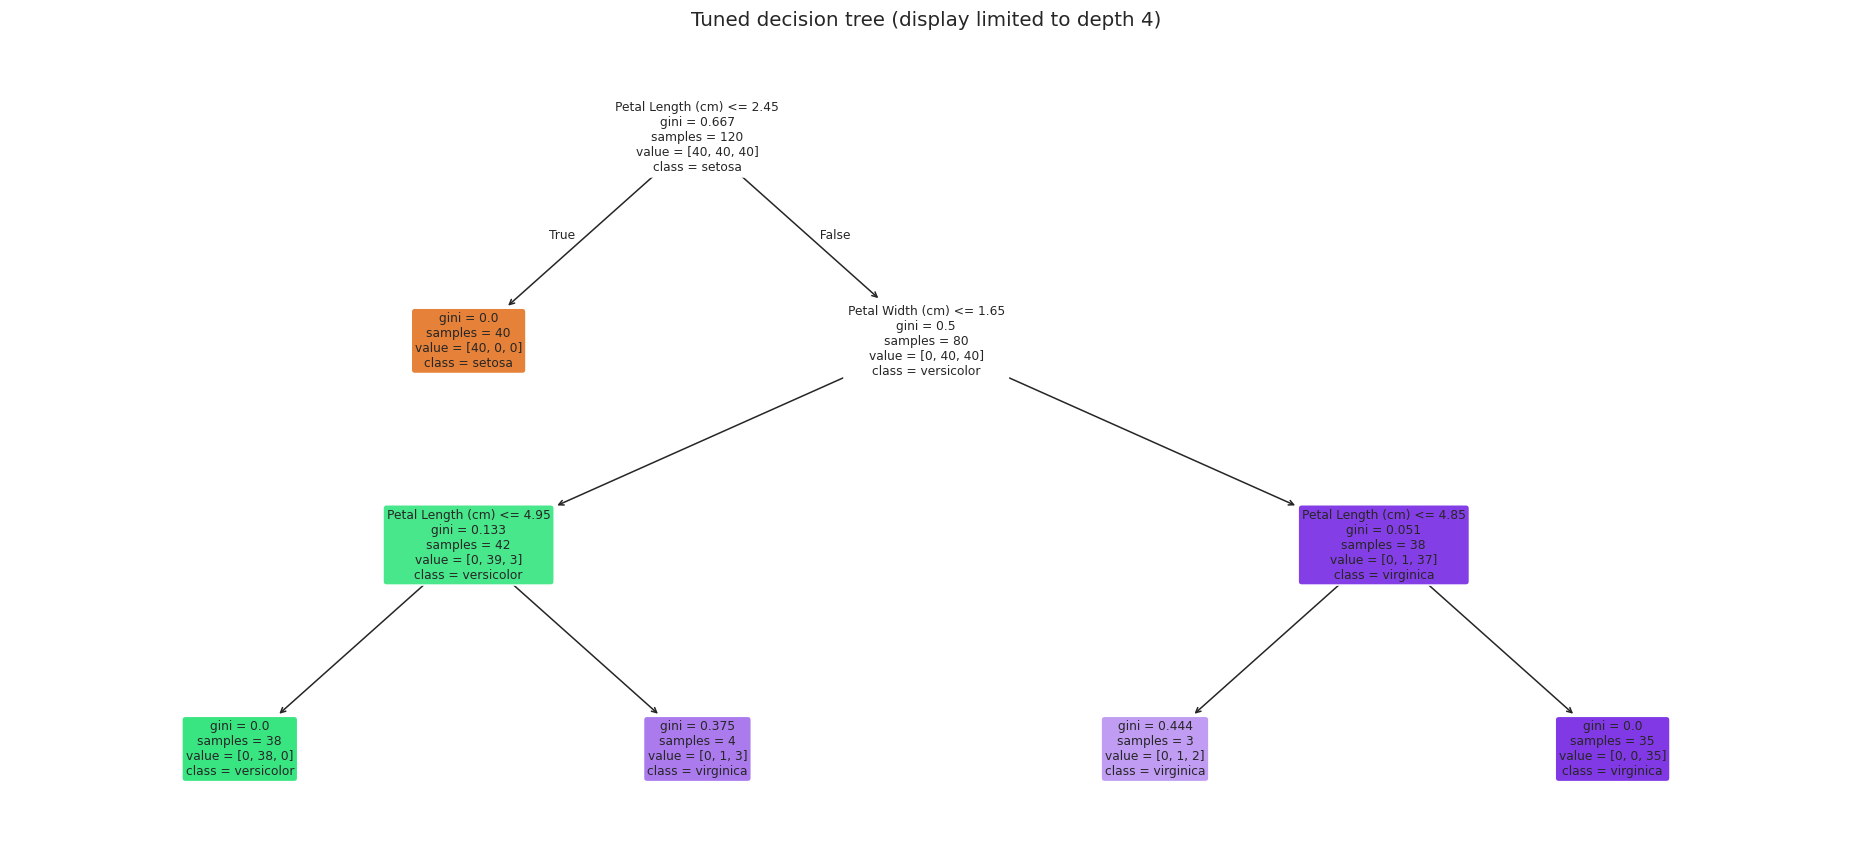

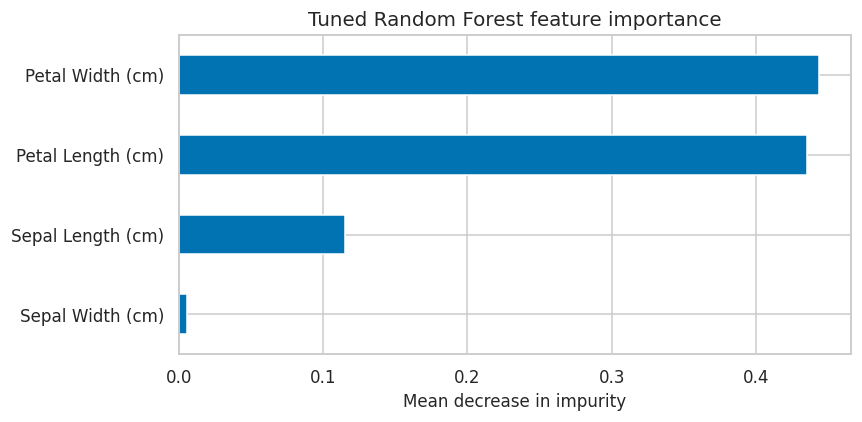

In [ ]:
tree = searches[('All 4 features', 'Decision Tree')].best_estimator_.named_steps['model']
plt.figure(figsize=(17, 8))
plot_tree(tree, feature_names=feature_names, class_names=list(iris.target_names), filled=True, rounded=True, fontsize=8, max_depth=4)
plt.title('Tuned decision tree (display limited to depth 4)'); plt.tight_layout(); plt.show()
forest = searches[('All 4 features', 'Random Forest')].best_estimator_.named_steps['model']
pd.Series(forest.feature_importances_, index=feature_names).sort_values().plot.barh(figsize=(8, 4), title='Tuned Random Forest feature importance')
plt.xlabel('Mean decrease in impurity'); plt.tight_layout(); plt.show()

## 11. Predict a new flower
This illustrative input is a flower with sepal length 5.8 cm, sepal width 2.7 cm, petal length 5.1 cm, and petal width 1.9 cm. Input order matches the original training columns.

In [ ]:
new_flower = pd.DataFrame([[5.8, 2.7, 5.1, 1.9]], columns=feature_names)
display(new_flower)
new_class = int(best_model.predict(new_flower)[0])
print('Predicted species:', iris.target_names[new_class])
if hasattr(best_model, 'predict_proba'):
    probs = pd.DataFrame([best_model.predict_proba(new_flower)[0]], columns=iris.target_names)
    print('Estimated class probabilities (model scores, not guaranteed calibrated):')
    display(probs.round(3))

,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm)
0,5.8,2.7,5.1,1.9


Predicted species: virginica
Estimated class probabilities (model scores, not guaranteed calibrated):


,setosa,versicolor,virginica
0,0.0,0.0,1.0


## 12. Executive summary and conclusions

In [ ]:
best_cv = searches[('All 4 features', best_name)].best_score_
best_test = accuracy_score(y_test, best_model.predict(X_test))
selected_top = list(X_train.columns[selector.get_support()])
all_best = cv_results.loc[cv_results['Feature Set'] == 'All 4 features', 'CV Mean Accuracy'].max()
two_best = cv_results.loc[cv_results['Feature Set'] == 'Selected 2 features', 'CV Mean Accuracy'].max()
summary = f"""### Project findings

- **Dataset:** {len(df)} flowers, {len(feature_names)} measurements, and {len(iris.target_names)} equally represented species.
- **EDA:** Petal length and petal width provide visually strong species separation, while sepal measurements overlap more.
- **Training-only ANOVA top two:** {selected_top[0]} and {selected_top[1]}. Feature importance is method-dependent.
- **Best four-feature CV accuracy:** {all_best:.3f}; **best two-feature CV accuracy:** {two_best:.3f}.
- **Recommended four-feature classifier:** **{best_name}** with training CV accuracy **{best_cv:.3f}** and held-out test accuracy **{best_test:.3f}**.
- **Interpretation:** A smaller feature set may improve simplicity but should be preferred only if its cross-validated performance remains competitive.
- **Limitations:** 150 flowers, 30 test observations, historical curated measurements, possible correlated predictors, and optimistic model-search CV scores. Results should not be generalized to all real-world flower photographs or environments.
- **Next steps:** Validate on an independent larger dataset, examine confidence intervals, use nested cross-validation, check model calibration, and monitor performance on new field measurements.
"""
display(Markdown(summary))

### Project findings

- **Dataset:** 150 flowers, 4 measurements, and 3 equally represented species.
- **EDA:** Petal length and petal width provide visually strong species separation, while sepal measurements overlap more.
- **Training-only ANOVA top two:** Petal Length (cm) and Petal Width (cm). Feature importance is method-dependent.
- **Best four-feature CV accuracy:** 0.967; **best two-feature CV accuracy:** 0.967.
- **Recommended four-feature classifier:** **K-Nearest Neighbors** with training CV accuracy **0.967** and held-out test accuracy **0.933**.
- **Interpretation:** A smaller feature set may improve simplicity but should be preferred only if its cross-validated performance remains competitive.
- **Limitations:** 150 flowers, 30 test observations, historical curated measurements, possible correlated predictors, and optimistic model-search CV scores. Results should not be generalized to all real-world flower photographs or environments.
- **Next steps:** Validate on an independent larger dataset, examine confidence intervals, use nested cross-validation, check model calibration, and monitor performance on new field measurements.


---
### Reproducibility checklist

- Dataset: `sklearn.datasets.load_iris()` (offline, built-in)
- Random seed: 42; split: 80/20 stratified
- Tuning: five-fold stratified CV on training rows only
- Learned scaling and two-feature selection: inside pipelines
- Final test: never used for tuning or feature ranking
- Outputs: descriptive tables, histograms, KDEs, boxplots, violins, pairplot, scatterplots, correlation heatmap, feature rankings, CV tables, confusion matrices, classification reports, model comparison, decision tree, prediction, and generated conclusion

**Dependencies:** `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, `ipython`, `jupyter`.